In [1]:
import os
import base64
from io import BytesIO

import requests
from PIL import Image
from dotenv import load_dotenv
from IPython.display import display

load_dotenv()
api_key = os.getenv("OPENROUTER_API_KEY")
if not api_key:
    raise ValueError("OPENROUTER_API_KEY was not found. Add it to your .env file.")

Image dimensions: (384, 256)
Compressed image: 6.6 KB


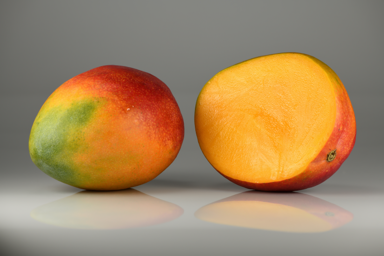

In [2]:
# Download the image, resize it, and encode it as a compact data URL.
image_url = (
    "https://commons.wikimedia.org/wiki/Special:Redirect/file/"
    "Mangos_-_single_and_halved.jpg"
)

download = requests.get(
    image_url,
    headers={"User-Agent": "MultimodalImageTest/1.0"},
    timeout=30,
)
download.raise_for_status()

img = Image.open(BytesIO(download.content)).convert("RGB")
img.thumbnail((384, 384))

buffer = BytesIO()
img.save(buffer, format="JPEG", quality=65, optimize=True)
small_image = buffer.getvalue()
image_b64 = base64.b64encode(small_image).decode("utf-8")
data_url = f"data:image/jpeg;base64,{image_b64}"

print("Image dimensions:", img.size)
print(f"Compressed image: {len(small_image) / 1024:.1f} KB")
display(img)

In [3]:
# Send the image and prompt to OpenRouter.
api_url = "https://openrouter.ai/api/v1/chat/completions"
headers = {
    "Authorization": f"Bearer {api_key}",
    "Content-Type": "application/json",
}

payload = {
    "model": "nvidia/nemotron-3.5-super-vl:free",
    "messages": [
        {
            "role": "user",
            "content": [
                {
                    "type": "text",
                    "text": "Identify the fruit in this image. Reply in one short sentence.",
                },
                {
                    "type": "image_url",
                    "image_url": {"url": data_url},
                },
            ],
        }
    ],
    "max_tokens": 500,
    "reasoning": {"effort": "low"},
}

response = requests.post(api_url, headers=headers, json=payload, timeout=60)
print("HTTP status:", response.status_code)
result = response.json()

if not response.ok:
    raise RuntimeError(f"OpenRouter request failed: {result}")

choice = result["choices"][0]
answer = choice["message"].get("content")
print("Model selected:", result.get("model"))
if answer:
    print("Answer:", answer)
else:
    print("No final text was returned. Finish reason:", choice.get("finish_reason"))
    print("Try running again later or selecting another available free vision model.")

HTTP status: 200
Model selected: nvidia/nemotron-3.5-super-vl:free
Answer: The fruit shown is a mango.
